# Lab 7 part 2
## Task 1

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']
listings = pd.read_csv('../data/listings_clean.csv', parse_dates=date_columns)
print(listings.shape)

(4574, 73)


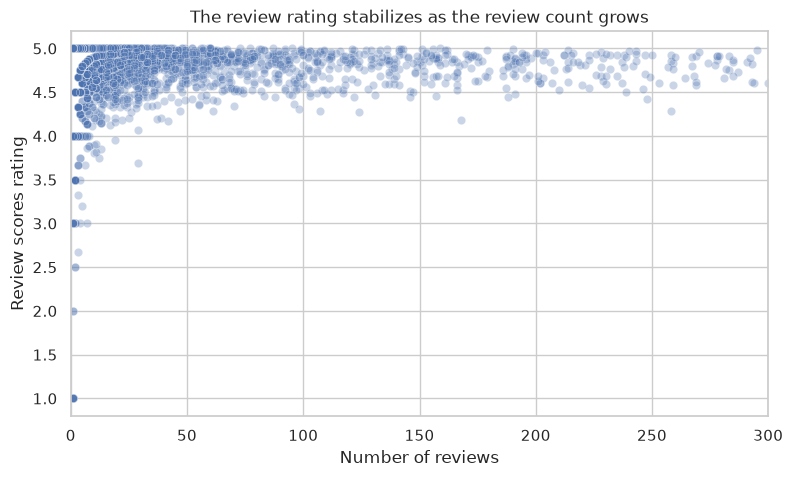

In [2]:
data = listings[listings["has_reviews"]]

x_limit = 300
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=data, x='number_of_reviews', y='review_scores_rating', alpha=0.3, ax=ax)
ax.set_xlim(0, x_limit)

ax.set_title('The review rating stabilizes as the review count grows')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Review scores rating')

plt.show()

In [3]:
print("Number of values greater than the diagram limit", (data["number_of_reviews"] > x_limit).sum())

Number of values greater than the diagram limit 91


The data point cloud is shaped as if curving around a rounded corner. For small values it is spread out on values from 1.0 to 5.0. For values larger than 40 the datapoints gather in the 4.0-5.0 range, and further on for values larger than 100 it is mostly in the 4.5-5.0 range. There are 91 data points outside of the diagram x limit.

## Task 2

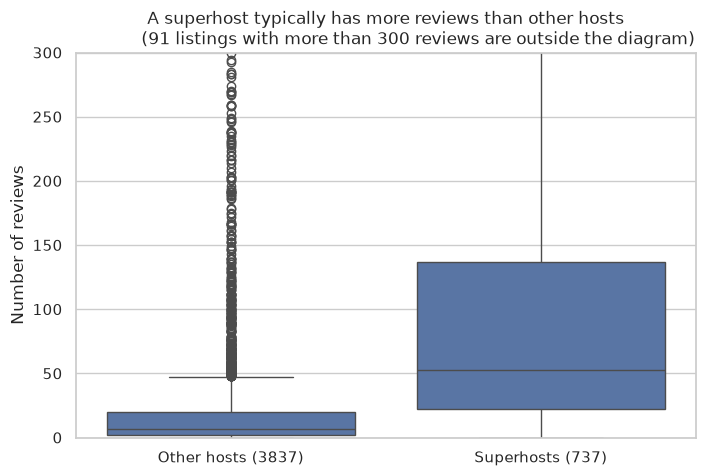

In [17]:
superhosts_count = listings["host_is_superhost"].sum()
other_hosts_count = (~listings["host_is_superhost"]).sum()
y_limit = 300
count_above_limit = (listings["number_of_reviews"] > y_limit).sum()

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=listings, x='host_is_superhost', y='number_of_reviews', ax=ax)

ax.set_ylim(0, y_limit)
ax.set_title(f'A superhost typically has more reviews than other hosts\n\
             ({count_above_limit} listings with more than {y_limit} reviews are outside the diagram)')

ax.set_xticks([False, True])
ax.set_xticklabels([f"Other hosts ({other_hosts_count})", f"Superhosts ({superhosts_count})"])
ax.set_xlabel('')
ax.set_ylabel('Number of reviews')

plt.show()

You can say that superhosts typically have more reviews than other hosts.  
You cannot say that if you have a large number of reviews then you are a superhost.

## Task 3

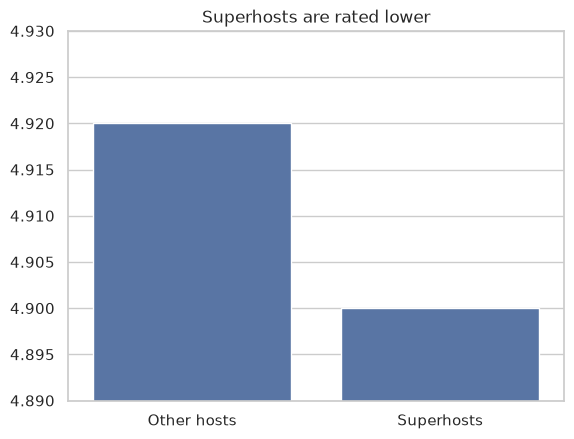

In [24]:

medians = listings.groupby('host_is_superhost')['review_scores_rating'].median()
fig, ax = plt.subplots()
sns.barplot(x=['Other hosts', 'Superhosts'], y=medians.values, ax=ax)
ax.set_ylim(4.89, 4.93)
ax.set_title('Superhosts are rated lower')
plt.show()

a) Things that are wrong with this diagram:
1. The y-axis does not start from 0, making the difference look much bigger than it is.
2. The only value used for the conclusion is the median, and it is does not say that the median is used in the diagram.
3. The counts for each group is not displayed.
4. The y-axis does not have a label.

b)

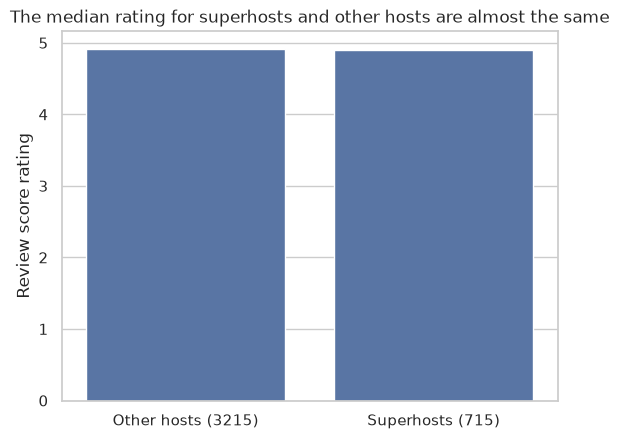

In [29]:
medians = listings.groupby('host_is_superhost')['review_scores_rating'].median()
superhosts_count = (listings["host_is_superhost"] & listings['review_scores_rating']).sum()
other_hosts_count = (~listings["host_is_superhost"] & listings['review_scores_rating']).sum()

fig, ax = plt.subplots()
sns.barplot(x=[f'Other hosts ({other_hosts_count})', f'Superhosts ({superhosts_count})'], y=medians.values, ax=ax)
ax.set_title('The median rating for superhosts and other hosts are almost the same')
ax.set_ylabel('Review score rating')
plt.show()